In [1]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
import pickle

from utils import *

In [235]:
flopp_flopp_e_pivot = pd.read_csv('processed_data/flopp_flopp_e_pivot.csv')
slopp_slopp_e_pivot = pd.read_csv('processed_data/slopp_slopp_e_pivot.csv')

In [239]:
slopp_slopp_e_pivot.iloc[:,3:-1]

,0.0,2.167788617886179,4.335577235772358,6.503365853658536,8.671154471544716,10.838943089430895,13.006731707317073,15.174520325203252,17.34230894308943,19.51009756097561,...,3980.059902439024,3982.227691056911,3984.3954796747967,3986.563268292683,3988.73105691057,3990.8988455284552,3993.0666341463416,3995.234422764228,3997.402211382114,3999.57
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000,0.000000,0.000,0.000,0.000000,0.000000,0.000
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000,0.000000,0.000,0.000,0.000000,0.000000,0.000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000,0.000000,0.000,0.000,0.000000,0.000000,0.000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000,0.000000,0.000,0.000,0.000000,0.000000,0.000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000,0.000000,0.000,0.000,0.000000,0.000000,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
256,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000,0.000000,0.000,0.000,0.000000,0.000000,0.000
257,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,334.563808,318.184656,314.027482,302.838,392.545613,302.838,302.838,305.766156,305.004105,302.838
258,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000,0.000000,0.000,0.000,0.000000,0.000000,0.000
259,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000,0.000000,0.000,0.000,0.000000,0.000000,0.000


In [290]:
spectra_data = pd.read_csv('gloves_contamination/data_ir.csv')
del spectra_data['Unnamed: 0']
spectra_data

,948.0,950.0,952.0,954.0,956.0,958.0,960.0,962.0,964.0,966.0,...,2996.0,2998.0,3000.0,3002.0,id,map_x,map_y,brand,run,day
0,-3.305811,-2.244836,-1.808550,-1.441703,-1.005475,-0.666216,-0.634051,-0.344357,-0.414275,-0.538892,...,-1.364635,-1.015415,-3.303930,-3.520125,CR_01_0319_1,-2968.649902,-2010.150024,CR,1,319
1,1.589247,0.587879,-0.132626,0.832453,0.197233,0.157895,-0.055195,-0.236536,-0.073942,0.058277,...,1.244847,0.068627,-0.406120,-1.435895,CR_01_0319_2,-2970.300049,-2006.150024,CR,1,319
2,1.536974,-0.241123,0.317267,-0.392871,-0.077576,0.261614,0.017024,0.120983,-0.054634,-0.082392,...,-0.452987,-0.312717,0.512639,0.211609,CR_01_0319_3,-2960.850098,-2002.000000,CR,1,319
3,0.429390,-0.283086,-0.152739,0.169562,0.283499,-0.085923,-0.137004,-0.470308,-0.018342,0.125664,...,-1.260288,-1.706861,0.463105,-0.235947,CR_01_0319_4,-2946.300049,-1993.800049,CR,1,319
4,-0.851665,0.260913,-0.934513,-0.355387,-0.081696,-0.180108,-0.279048,-0.394081,-0.266153,0.385534,...,-0.206879,0.536171,-0.477935,-0.128079,CR_01_0319_5,-2935.000000,-1992.449951,CR,1,319
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,-0.060284,0.557875,0.459524,0.306358,0.177851,0.499784,0.440978,-0.025045,-0.020101,-0.063076,...,0.213426,0.801208,0.832383,0.793913,KC_02_0328_28,-4543.500000,-1759.750000,KC,2,328
726,-0.224498,-1.765926,-1.666877,-0.438259,0.020466,-0.033487,-0.052281,-0.242959,-0.138028,-0.317322,...,-0.163860,0.123000,-1.466878,-1.311235,KC_02_0328_29,-4501.899902,-1758.099976,KC,2,328
727,-1.435758,-1.585154,-1.323444,-0.828181,-1.129116,-0.718950,-0.295729,0.029341,-0.312350,-0.225063,...,-1.668260,-2.328258,-2.125748,-1.402201,KC_02_0328_30,-4510.850098,-1747.099976,KC,2,328
728,0.572048,0.026594,0.111077,0.057758,-0.151336,0.168770,0.375415,0.252623,0.012098,0.329679,...,13.735632,10.824211,9.217921,8.421560,KC_02_0328_31,-4511.100098,-1743.050049,KC,2,328


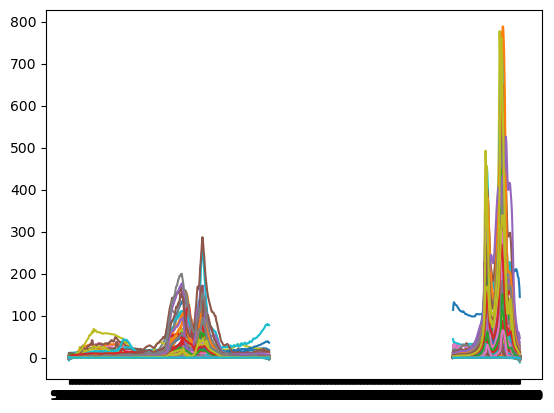

In [629]:
plt.plot(spectra_data.iloc[:,:-6].T)

In [292]:
spectra_data_long = spectra_data.iloc[:, :-5].melt(id_vars='id')#
spectra_data_long.iloc[:,1:] = spectra_data_long.iloc[:,1:].astype('float32')

spectra_data_long.columns = ['file_name','wavelength','intensity']
spectra_data_long['polymer'] = ''
spectra_data_long_int = interpol_spect(spectra_data_long, min_wl=674.9918, max_wl=3999.809,n=1725)
spectra_data_int = spectra_data_long_int.pivot(
    index=['file_name'], 
    columns='wavelength', 
    values='intensity').reset_index()

In [293]:
spectra_data_raman = pd.read_csv('gloves_contamination/data_raman.csv')
del spectra_data_raman['Unnamed: 0']
spectra_data_raman

,326.1221507938171,329.5937686606638,333.0653865275105,336.53700439435715,340.00862226120387,343.4802401280505,346.95185799489724,350.4234758617439,353.8950937285906,357.36671159543727,...,3867.172374977435,3870.643992844282,3874.1156107111287,3877.587228577975,id,map_x,map_y,brand,run,day
0,1794.666626,1752.576660,1763.867920,1770.988159,1760.301270,1780.839722,1821.787842,1851.077026,1902.091431,1986.960083,...,1915.923950,1903.408569,1907.495483,1935.333374,CR_01_0319_1,-2968.649902,-2010.150024,CR,1,319
1,1746.000000,1738.108154,1738.719604,1728.901245,1723.339966,1790.221680,1800.465454,1819.483765,1862.178711,1923.559814,...,1822.359131,1809.253662,1817.538452,1836.000000,CR_01_0319_2,-2970.300049,-2006.150024,CR,1,319
2,1693.333374,1678.601807,1690.596191,1700.998657,1703.744873,1724.809937,1767.777222,1817.423218,1859.007324,1889.279053,...,1822.127808,1831.702393,1844.551758,1852.000000,CR_01_0319_3,-2960.850098,-2002.000000,CR,1,319
3,1682.666626,1682.666626,1683.055176,1687.839355,1699.855225,1721.446899,1756.486328,1792.688843,1846.801758,1919.419434,...,1894.718506,1867.576660,1906.510620,1948.666626,CR_01_0319_4,-2946.300049,-1993.800049,CR,1,319
4,1676.666626,1625.106323,1642.804077,1657.573120,1658.452637,1724.281128,1722.777832,1760.537964,1828.128784,1900.987183,...,1804.616333,1792.200928,1803.889282,1831.333374,CR_01_0319_5,-2935.000000,-1992.449951,CR,1,319
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,1690.000000,1691.578369,1707.541016,1733.436035,1761.970337,1780.928955,1803.883301,1838.169067,1884.668823,1948.736694,...,1985.039673,1946.911865,1915.723267,1953.333374,KC_02_0328_28,-4543.500000,-1759.750000,KC,2,328
726,1645.000000,1689.983765,1721.037842,1735.167358,1739.970337,1758.928955,1811.226807,1865.521118,1910.321899,1949.599609,...,2002.001099,2001.886353,1985.557129,2046.000000,KC_02_0328_29,-4501.899902,-1758.099976,KC,2,328
727,1812.666626,1845.812622,1844.176392,1858.945923,1900.080688,1919.565796,1945.534058,1995.863770,2034.421631,2052.350830,...,2281.691895,2312.100586,2284.014648,2202.000000,KC_02_0328_30,-4510.850098,-1747.099976,KC,2,328
728,2240.000000,2258.940430,2259.337646,2271.395264,2306.098877,2349.545654,2372.142578,2382.757080,2408.785156,2467.679443,...,2814.306396,2856.691895,2870.166016,2899.000000,KC_02_0328_31,-4511.100098,-1743.050049,KC,2,328


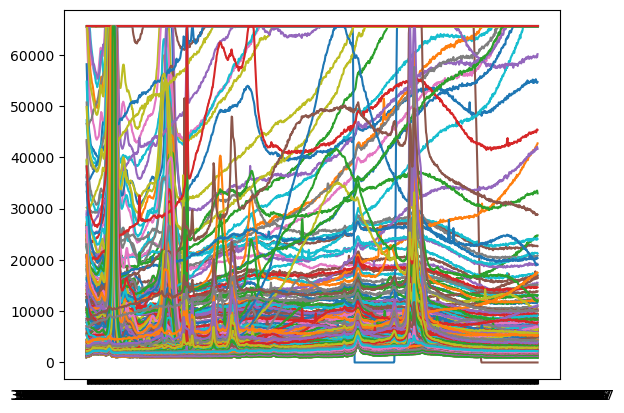

In [295]:
plt.plot(spectra_data_raman.iloc[:,:-6].T)

In [297]:
spectra_data_raman_long = spectra_data_raman.iloc[:, :-5].melt(id_vars='id')#
spectra_data_raman_long.iloc[:,1:] = spectra_data_raman_long.iloc[:,1:].astype('float32')

spectra_data_raman_long.columns = ['file_name','wavelength','intensity']
spectra_data_raman_long['polymer'] = ''
spectra_data_raman_long_int = interpol_spect(spectra_data_raman_long, min_wl=0, max_wl=3999.57,n=1846)
spectra_data_raman_int = spectra_data_raman_long_int.pivot(
    index=['file_name'], 
    columns='wavelength', 
    values='intensity').reset_index()

In [298]:
spectra_data_raman_int

wavelength,file_name,0.0,2.167788617886179,4.335577235772358,6.503365853658536,8.671154471544716,10.838943089430895,13.006731707317073,15.174520325203252,17.34230894308943,...,3980.0599024390244,3982.2276910569108,3984.3954796747967,3986.563268292683,3988.7310569105694,3990.8988455284552,3993.0666341463416,3995.234422764228,3997.402211382114,3999.57
0,CR_01_0319_1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,CR_01_0319_10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,CR_01_0319_100,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,CR_01_0319_101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,CR_01_0319_102,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,MF_01_0405_95,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
726,MF_01_0405_96,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
727,MF_01_0405_97,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
728,MF_01_0405_98,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [478]:
wl_list = np.float64(spectra_data_int.columns[1:])
wl_list_1 = np.float64(spectra_data.columns[:-6])
wl_list_2 = np.float64(spectra_data_int.columns[1:])

idx_range = np.logical_or(
    np.logical_and(
        wl_list_2 > wl_list_1.min(),
        wl_list_2 < np.float32((wl_list_1[np.where(np.isnan(np.float32(spectra_data.iloc[0,:-6])))])).min()-1, #-1
    ),
    np.logical_and(
        wl_list > np.float32((wl_list_1[np.where(np.isnan(np.float32(spectra_data.iloc[0,:-6])))])).max()+1,
        wl_list < wl_list_1.max(),
    )
)
import pickle 
filename = 'gloves_contamination/idx_range.sav'
pickle.dump(idx_range, open(filename, 'wb'))

In [309]:
wl_list = np.float64(spectra_data_raman_int.columns[1:])
wl_list_1 = np.float64(spectra_data_raman.columns[:-6])
wl_list_2 = np.float64(spectra_data_raman_int.columns[1:])

idx_range_raman = np.logical_or(
    np.logical_and(
        wl_list_2 > wl_list_1.min(),
        wl_list_2 < np.float32((wl_list_1[np.where(np.isnan(np.float32(spectra_data.iloc[0,:-6])))])).min()-1, #-1
    ),
    np.logical_and(
        wl_list > np.float32((wl_list_1[np.where(np.isnan(np.float32(spectra_data.iloc[0,:-6])))])).max()+1,
        wl_list < wl_list_1.max(),
    )
)
import pickle 
filename = 'gloves_contamination/idx_range_raman.sav'
pickle.dump(idx_range_raman, open(filename, 'wb'))

In [463]:
def norm_spect_pivot(x, norm_type='SNV'):
    if norm_type=='SNV':
        return (x - x.mean(1)[:,None]) / x.std(1)[:,None]
    if norm_type=='MINMAX':
        return (x - x.min(1)[:,None]) / (x.max(1)[:,None] - x.min(1)[:,None])
    if norm_type=='Q':
        iqr = np.quantile(x, .8, axis=1)-np.quantile(x, .2, axis=1)
        return (x - np.median(x, 1)[:,None]) / iqr[:,None]

In [634]:
x_train = flopp_flopp_e_pivot.iloc[:,4:].to_numpy()
#x_train = (x_train - x_train.mean(1)[:,None]) / x_train.std(1)[:,None]
x_train = norm_spect_pivot(x_train, norm_type='SNV') #MINMAX
x_train = -x_train[:,idx_range]
x_train_diff = np.diff(x_train)

x_train_diff = (x_train_diff - x_train_diff.mean(1)[:,None]) / x_train_diff.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)
y_train = flopp_flopp_e_pivot.iloc[:,2]


In [635]:
spectra_data_np = np.float32(spectra_data_int.iloc[:,1:].to_numpy())
#spectra_data_np_norm = (spectra_data_np[:,idx_range] - spectra_data_np[:,idx_range].mean(1)[:,None]) / spectra_data_np[:,idx_range].std(1)[:,None]
spectra_data_np = spectra_data_np[:,idx_range]
spectra_data_np_norm = norm_spect_pivot(spectra_data_np, norm_type='SNV') #MINMAX


spectra_data_diff = np.diff(spectra_data_np_norm)
spectra_data_diff = (spectra_data_diff - spectra_data_diff.mean(1)[:,None]) / spectra_data_diff.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)


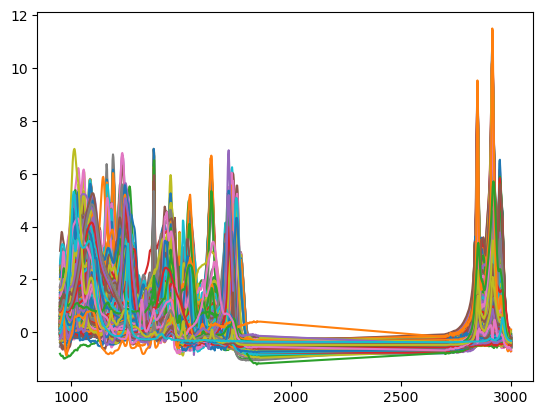

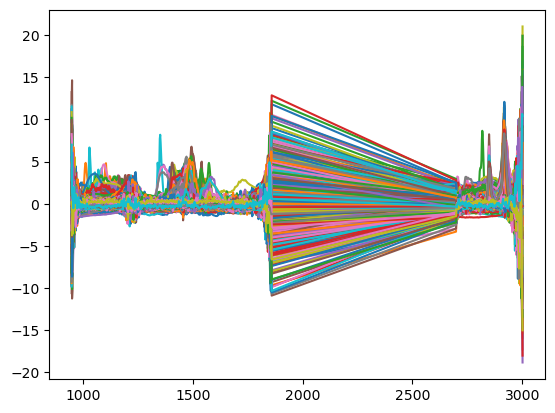

In [636]:
_ = plt.plot(wl_list[idx_range], x_train.T)
_ = plt.show()
_ = plt.plot(wl_list[idx_range], spectra_data_np_norm.T)

In [589]:
pred_ = corr_matching(x_train, y_train, 
                      spectra_data_np_norm, r_min=0)
pred_polymers = pred_[0]
pred_hqi = pred_[1]
pred_df = pd.DataFrame(pred_polymers)
pred_df['hqi'] = pred_hqi
pred_df.reset_index().groupby('polymer').count()

,index,hqi
polymer,,
Acrylic,1,1
Acrylonitrile Butadiene Styrene,10,10
Ethylene Acrylic Acid,1,1
Polyamide,6,6
Polycarbonate,11,11
Polyethylene,325,325
Polyethylene Terephthalate,4,4
Polyethylene Vinyl Acetate,7,7
Polymethyl Methacrylate,2,2


In [590]:
x_train = slopp_slopp_e_pivot.iloc[:,3:-1].to_numpy()
x_train = x_train[:,idx_range_raman]
#x_train = (x_train - x_train.mean(1)[:,None]) / x_train.std(1)[:,None]
x_train = norm_spect_pivot(x_train, norm_type='Q')

x_train_diff = np.diff(x_train)
x_train_diff = (x_train_diff - x_train_diff.mean(1)[:,None]) / x_train_diff.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)
y_train = slopp_slopp_e_pivot.iloc[:,2]


In [591]:
spectra_data_raman_np = np.float32(spectra_data_raman_int.iloc[:,1:].to_numpy())
#spectra_data_raman_np_norm = (spectra_data_raman_np[:,idx_range_raman] - spectra_data_raman_np[:,idx_range_raman].mean(1)[:,None]) / spectra_data_raman_np[:,idx_range_raman].std(1)[:,None]
spectra_data_raman_np_norm = norm_spect_pivot(spectra_data_raman_np[:,idx_range_raman], norm_type='Q') #MINMAX

spectra_data_raman_diff = np.diff(spectra_data_raman_np_norm)
spectra_data_raman_diff = (spectra_data_raman_diff - spectra_data_raman_diff.mean(1)[:,None]) / spectra_data_raman_diff.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)


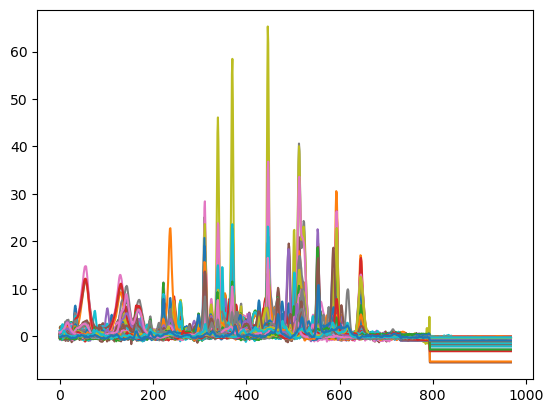

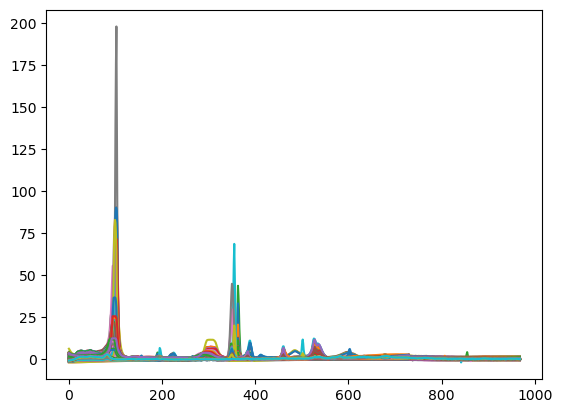

In [592]:
_ = plt.plot(x_train.T)
_ = plt.show()
_ = plt.plot(spectra_data_raman_np_norm.T)

In [593]:
pred_raman = corr_matching(x_train, y_train, 
                      spectra_data_raman_np_norm, r_min=0)
pred_polymers_raman = pred_raman[0]
pred_hqi_raman = pred_raman[1]
pred_df_raman = pd.DataFrame(pred_polymers_raman)
pred_df_raman['hqi'] = pred_hqi_raman
pred_df_raman.reset_index().groupby('polymer').count()

,index,hqi
polymer,,
Acrylic,37,29
Acrylonitrile Butadiene Styrene,43,43
Cellulose Acetate,5,5
Cotton,76,76
Dyed Cellulose,69,69
Polyamide,4,4
Polyester,13,13
Polyethylene,325,325
Polyethylene Terephthalate,28,28


In [621]:
(pred_polymers[pred_hqi>.8].to_numpy() == pred_polymers_raman[pred_hqi>.8].to_numpy()).mean()


0.3827751196172249

In [649]:
labels = np.unique(np.concatenate([pred_polymers.to_numpy(), pred_polymers_raman.to_numpy()]))

In [655]:
np.unique(pred_polymers.to_numpy())

array(['Acrylic', 'Acrylonitrile Butadiene Styrene',
       'Ethylene Acrylic Acid', 'Polyamide', 'Polycarbonate',
       'Polyethylene', 'Polyethylene Terephthalate',
       'Polyethylene Vinyl Acetate', 'Polymethyl Methacrylate',
       'Polypropylene', 'Polystyrene', 'Polyurethane',
       'Polyvinyl Chloride', 'Rubber'], dtype=object)

In [650]:
confusion_matrix(pred_polymers, pred_polymers_raman, labels=labels)

array([[  0,   1,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0],
       [  1,   0,   1,   1,   0,   0,   0,   0,   0,   4,   1,   0,   0,
          0,   0,   2,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   0,
          0,   0,   0,   0,   0],
       [  2,   1,   0,   0,   1,   0,   0,   0,   0,   1,   0,   0,   0,
          0,   0,   1,   0,   0],
       [  1,   6,   0,   0,   0,   0,   0,   0,   0,   2,   0,   1,   0,
          1,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0],
       [ 16,  10,   0,  10,  61,   0,

<AxesSubplot: >

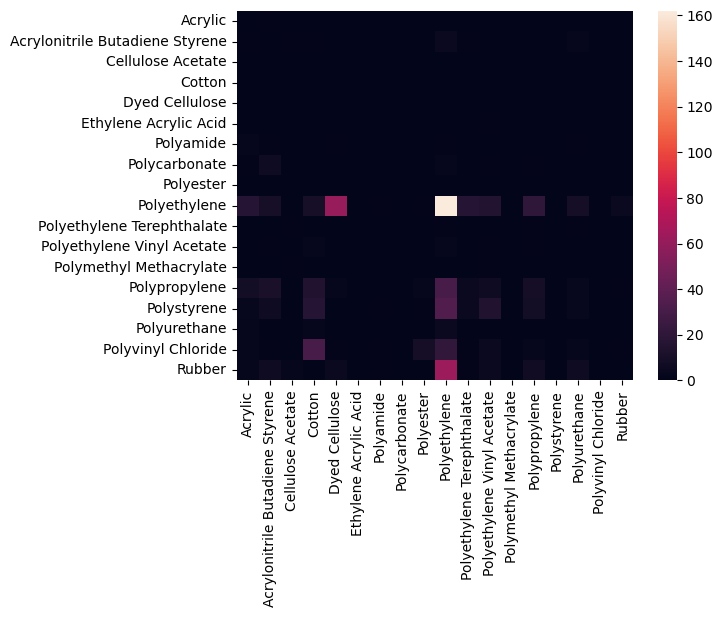

In [653]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

sns.heatmap(confusion_matrix(pred_polymers, pred_polymers_raman, labels=labels), xticklabels=labels, yticklabels=labels)

In [628]:
confusion_matrix(pred_polymers, pred_polymers_raman)

array([[  0,   1,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0],
       [  1,   0,   1,   1,   0,   0,   0,   0,   0,   4,   1,   0,   0,
          0,   0,   2,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   0,
          0,   0,   0,   0,   0],
       [  2,   1,   0,   0,   1,   0,   0,   0,   0,   1,   0,   0,   0,
          0,   0,   1,   0,   0],
       [  1,   6,   0,   0,   0,   0,   0,   0,   0,   2,   0,   1,   0,
          1,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0],
       [ 16,  10,   0,  10,  61,   0,

In [625]:
pd.DataFrame({'ir':pred_polymers[pred_hqi>.8].to_numpy(),
              'raman':pred_polymers_raman[pred_hqi>.8].to_numpy(),
              'n':1}).groupby(['ir','raman']).count()

n
ir                 raman                              
Polycarbonate      Acrylonitrile Butadiene Styrene   1
Polyethylene       Dyed Cellulose                   51
                   Polyamide                         1
                   Polyethylene                     78
                   Polyethylene Terephthalate        6
                   Polyethylene Vinyl Acetate        5
                   Polypropylene                     7
                   Polyurethane                      2
Polypropylene      Acrylic                           1
                   Acrylonitrile Butadiene Styrene   1
                   Cotton                            2
                   Dyed Cellulose                    2
                   Polyester                         2
                   Polyethylene                      7
                   Polyethylene Terephthalate        1
                   Polypropylene                     2
Polystyrene        Acrylic                           1
Polyurethane       Acrylic                           1
                   Polyethylene                      2
Polyvinyl Chloride Acrylonitrile Butadiene Styrene   1
Rubber             Acrylonitrile Butadiene Styrene   1
                   Dyed Cellulose                    3
                   Polyethylene                     25
                   Polyethylene Terephthalate        1
                   Polypropylene                     4
                   Polyurethane                      1

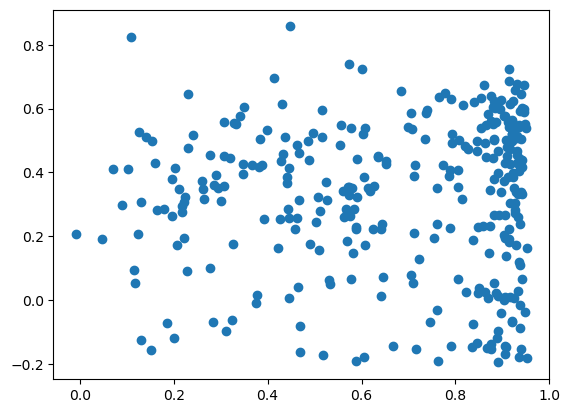

In [594]:
plt.scatter(pred_hqi[np.array(pred_polymers=='Polyethylene').flatten()], 
            pred_hqi_raman[np.array(pred_polymers=='Polyethylene').flatten()])

In [381]:
clf = LogisticRegression(random_state=0, C=5, penalty='l1', solver='saga')
clf.fit(x_train, y_train)
predict = clf.predict(spectra_data_np_norm)
pd.DataFrame({'polymer':predict, 'n':1}).groupby('polymer').count()

In [630]:
pd.DataFrame([pred_polymers.reset_index(drop=True),
              pd.Series(pred_hqi)]).T.groupby('polymer').mean()

,Unnamed 0
polymer,
Acrylic,0.497825
Acrylonitrile Butadiene Styrene,0.207854
Ethylene Acrylic Acid,0.207574
Polyamide,0.224934
Polycarbonate,0.463079
Polyethylene,0.665490
Polyethylene Terephthalate,0.065267
Polyethylene Vinyl Acetate,0.135779
Polymethyl Methacrylate,0.333641


Acrylic 23


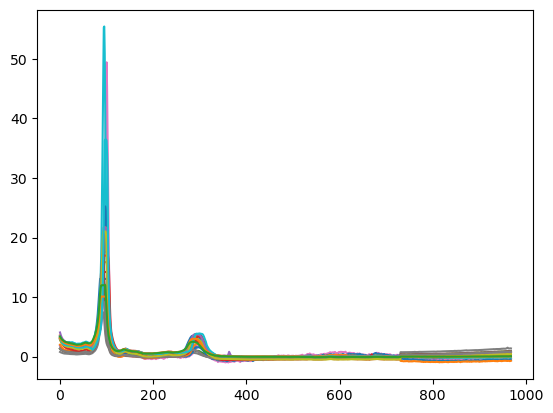

Acrylonitrile Butadiene Styrene 25


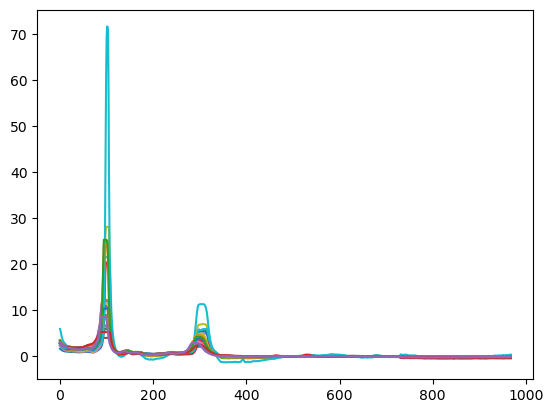

Cellulose Acetate 2


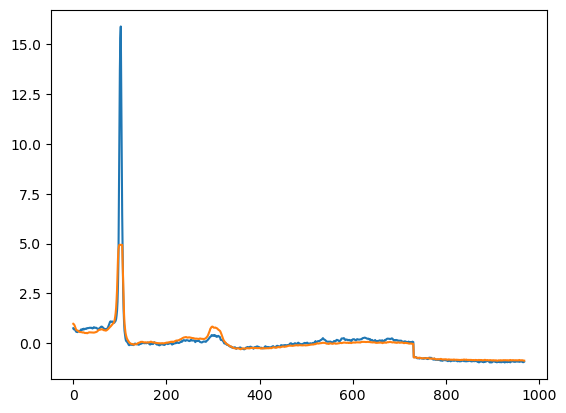

Cotton 28


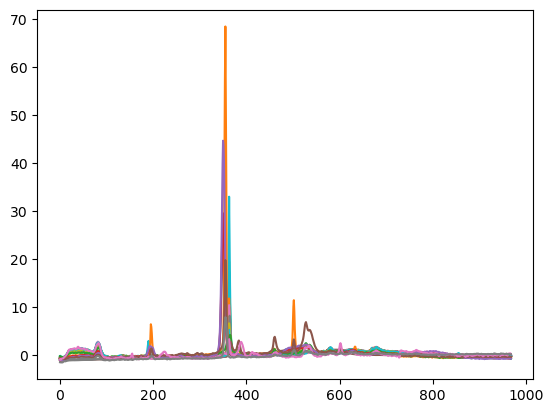

Dyed Cellulose 67


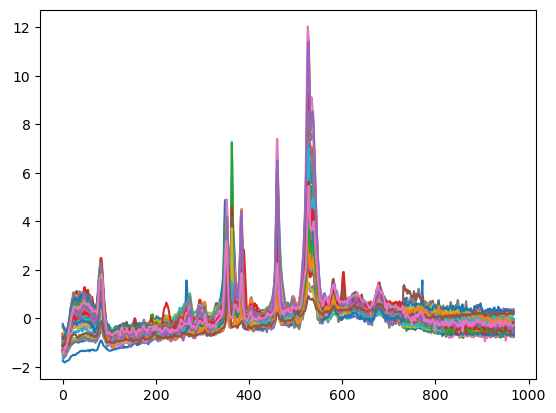

Polyamide 4


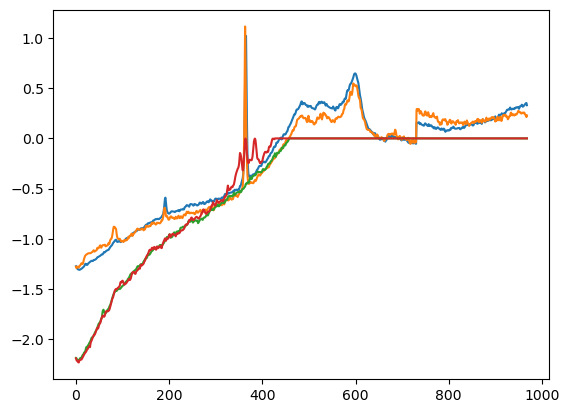

Polyester 12


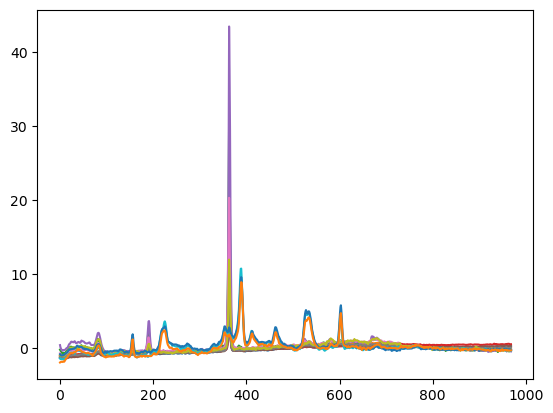

Polyethylene 201


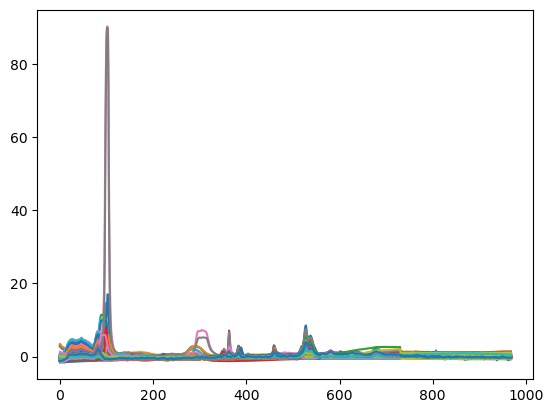

Polyethylene Terephthalate 15


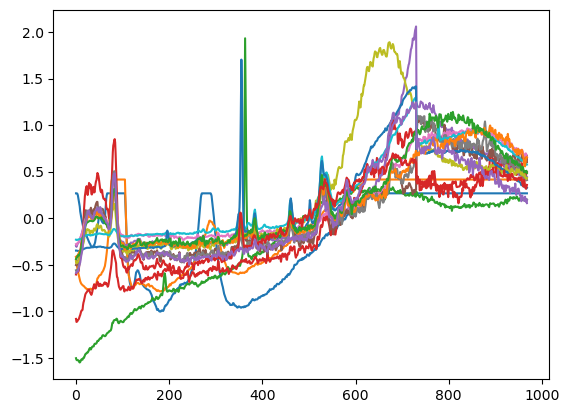

Polyethylene Vinyl Acetate 10


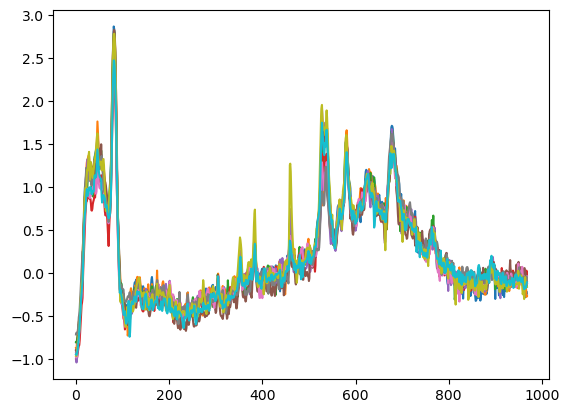

Polypropylene 19


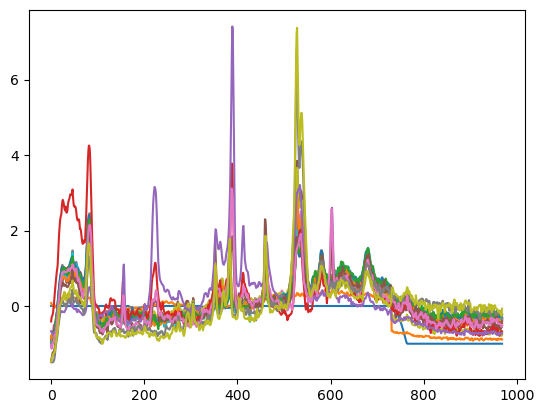

Polyurethane 8


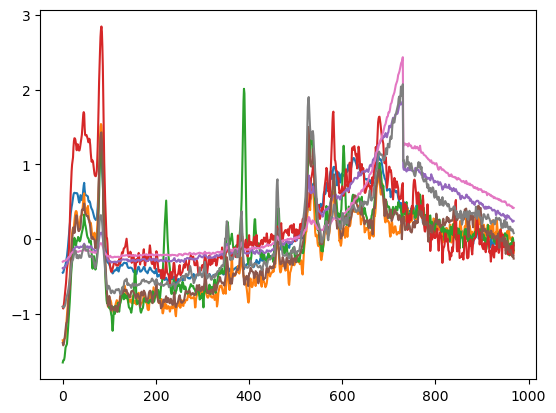

Rubber 4


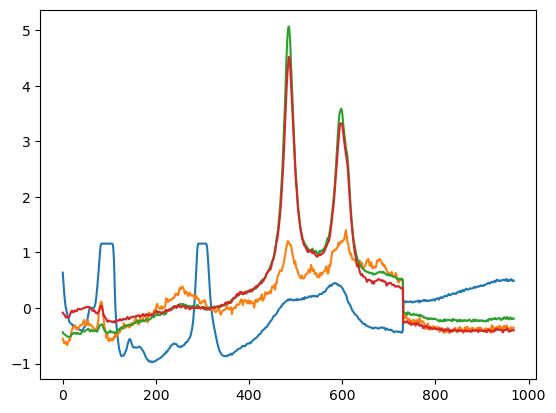

In [639]:
match_idx = pred_hqi>.4

for p in np.unique(pred_polymers_raman):
    
    idx = np.logical_and(match_idx, np.array(pred_polymers_raman)==p)
    if sum(idx) == 0:
        continue
    print(p, sum(idx))
    
    
    plt.plot(spectra_data_raman_np_norm[idx,:].T)
    plt.show()